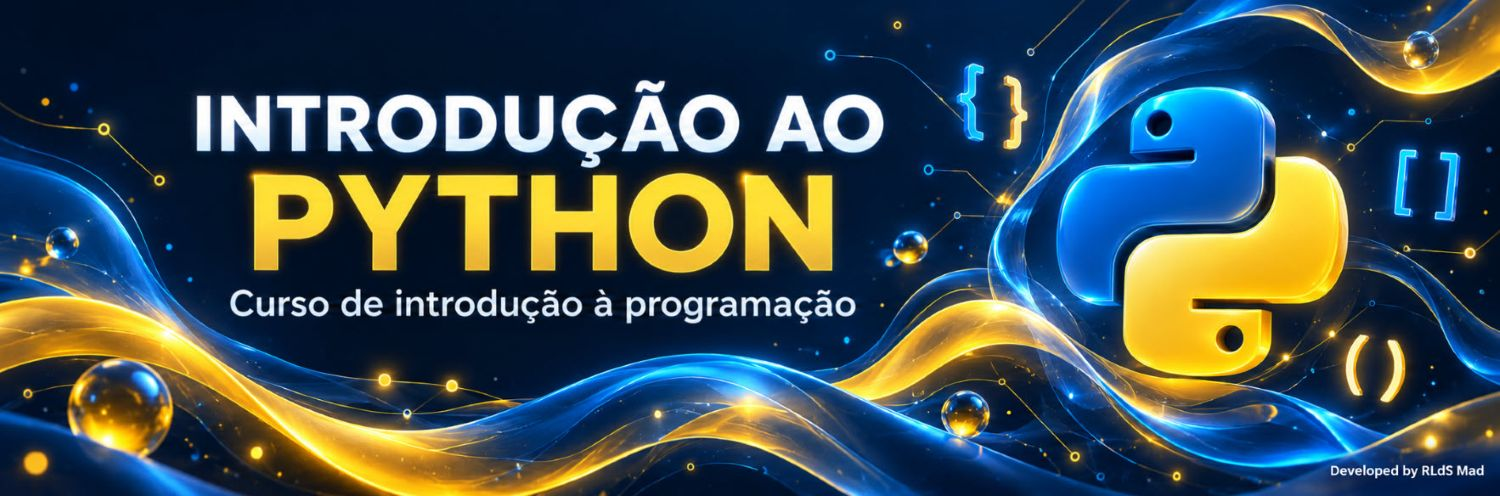

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_3_ia/RLdS_N3_01_Estatistica_Descritiva_Python.ipynb)


# Nível IA · Módulo 1 – Estatística descritiva com Python
## Da resolução à mão ao código: os exercícios 1 a 12

Na disciplina de Fundamentos de Estatística resolveste estes exercícios à mão, com o formulário e a calculadora. Aqui vais fazer o mesmo caminho em Python: cada fórmula passa a ser uma função curta, cada alínea passa a ser uma ou duas linhas de código, e no fim confirmas que o programa dá **os mesmos valores das soluções oficiais**.

Usamos só Python puro (listas, dicionários, funções, `math` e `collections.Counter`) e o matplotlib para os gráficos. 
Assim vês o que está por trás de cada cálculo. 
No módulo seguinte, os mesmos exercícios são resolvidos com NumPy, pandas e SciPy.

> **Objetivos:** traduzir fórmulas de estatística descritiva em funções Python; organizar tabelas de frequências como listas de dicionários; calcular medidas de localização, dispersão, assimetria e curtose em dados individuais, em tabelas valor/frequência e em classes; desenhar histogramas e diagramas de extremos e quartis; verificar resultados contra uma solução conhecida.

**Pré-requisitos:** o nível introdutório, em particular listas (cap. 12), dicionários (cap. 14), funções (cap. 18), expressões lambda (cap. 19) e visualização (cap. 24); e as noções de estatística descritiva da disciplina (frequências, média, quantis, desvio-padrão).

**Duração sugerida:** 4 a 6 horas.

### Como utilizar
Executa as células por ordem com `Shift + Enter`, ou usa *Executar tudo*. O notebook é autónomo: a biblioteca de funções está no Passo 1 e não precisas de mais nenhum ficheiro. Funciona em Jupyter, VS Code e Colab.

Cada exercício tem uma célula de texto com os dados e a **leitura** do enunciado (que funções usar e porquê) e uma célula de código com a resolução, alínea a alínea. Podes alterar os dados e voltar a executar.

**Convenções da disciplina**, seguidas em todo o notebook:
- variância e desvio-padrão com divisor n − 1;
- quantis de dados individuais pela posição p·(n + 1), com interpolação;
- classes pela regra de Sturges, na notação [a ; b[;
- quantis em classes por interpolação e moda em classes por Mo = L + h·n_seg/(n_ant + n_seg);
- assimetria de Pearson e de Bowley e curtose percentílica K, com referência 0,263.

### Índice
1. Passo 1 – Biblioteca de funções (sete blocos)
2. Passo 2 – Como ler uma alínea
3. Exercícios 1 a 12
4. Verificação automática contra as soluções oficiais
5. Experimenta, Verifica o que aprendeste e Leitura recomendada


## Passo 1 – Biblioteca de funções

A biblioteca está dividida em sete blocos, pela ordem das aulas. Executa as sete células de código por ordem; cada uma vem depois de uma tabela que explica as funções que define.

Convenção comum: as tabelas de frequências são **listas de dicionários**, uma linha por valor ou por classe, com as chaves `x` (ou `li`, `ls` e `c` nas classes), `n`, `N`, `f` e `F`. São exatamente as colunas do quadro de frequências dos slides. Assim, `tab[2]["N"]` lê a frequência acumulada da 3.ª linha.


In [ ]:
# Executar esta célula
  
"""Biblioteca de estatística descritiva, com as convenções da disciplina.

- variância e desvio-padrão amostrais (divisor n − 1)
- quantis de dados individuais pela posição k = p·(n + 1), com interpolação
- classes pela regra de Sturges, na notação [a ; b[
- quantis em classes por interpolação; moda em classes Mo = L + h·n_seg/(n_ant + n_seg)
- assimetria de Pearson e de Bowley; curtose percentílica K com referência 0,263
"""
import math
from collections import Counter

import matplotlib.pyplot as plt

### Bloco 1 – Tabelas de frequências

| Função | O que faz | Recebe | Devolve |
| --- | --- | --- | --- |
| `tabela_frequencias(dados)` | Conta quantas vezes aparece cada valor distinto (com `Counter`), ordena os valores e acumula. É o quadro de frequências de dados discretos. | lista de valores (ex. 2 e 4) | lista de linhas `{x, n, N, f, F}` |
| `tabela_agrupada(valores, freqs)` | Constrói a mesma tabela quando o enunciado já dá os pares valor/n.º (ex. 9 e 10), sem expandir os dados. | duas listas paralelas | lista de linhas `{x, n, N, f, F}` |
| `imprimir_tabela(linhas, titulo)` | Mostra a tabela alinhada em colunas; `titulo` é o nome da variável no cabeçalho. | tabela | nada (imprime) |

Fórmulas: fᵢ = nᵢ/n, Nᵢ = n₁ + … + nᵢ, Fᵢ = Nᵢ/n. Verificação rápida: a última linha tem N = n e F = 1.

```python
tab = tabela_frequencias([5, 7, 7, 8])
tab[1]            # {'x': 7, 'n': 2, 'N': 3, 'f': 0.5, 'F': 0.75}
```


In [ ]:
# Executar esta célula

def tabela_frequencias(dados):
    """Tabela de dados discretos: lista de dicionários com x, n, N, f, F."""
    n = len(dados)
    linhas, acumulado = [], 0
    for x, ni in sorted(Counter(dados).items()):
        acumulado += ni
        linhas.append({"x": x, "n": ni, "N": acumulado, "f": ni / n, "F": acumulado / n})
    return linhas


def tabela_agrupada(valores, freqs):
    """Tabela a partir de pares valor/frequência (ex. 9 e 10)."""
    n = sum(freqs)
    linhas, acumulado = [], 0
    for x, ni in sorted(zip(valores, freqs)):
        acumulado += ni
        linhas.append({"x": x, "n": ni, "N": acumulado, "f": ni / n, "F": acumulado / n})
    return linhas


def imprimir_tabela(linhas, titulo="x"):
    print(f"{titulo:>12} {'n':>6} {'N':>6} {'f':>8} {'F':>8}")
    for linha in linhas:
        print(f"{str(linha['x']):>12} {linha['n']:>6} {linha['N']:>6} "
              f"{linha['f']:>8.4f} {linha['F']:>8.4f}")

### Bloco 2 – Classes (dados contínuos)

| Função | O que faz | Recebe | Devolve |
| --- | --- | --- | --- |
| `sturges(n)` | Número de classes pela regra de Sturges, k = 1 + 3,3·log₁₀ n, **truncado** ao inteiro (28 → 5, 35 → 6, 80 → 7), como nas soluções oficiais. | n.º de observações | inteiro k |
| `classes_sturges(dados, k, amplitude, inicio)` | Divide os dados em k classes [a ; b[ de amplitude h a partir de `inicio`; a última classe é fechada dos dois lados para incluir o máximo. Sem `k`, usa `sturges`; sem `amplitude`, usa (máx − início)/k; sem `inicio`, usa o mínimo. | lista de valores e opções | lista de linhas `{li, ls, c, n, N, f, F}` |
| `classes_dadas(limites, freqs)` | Monta a tabela quando as classes já vêm no enunciado (ex. 3 e 12): `limites` tem k + 1 números e `freqs` tem k. | lista de limites, lista de nᵢ | lista de linhas `{li, ls, c, n, N, f, F}` |
| `imprimir_classes(linhas, casas)` | Mostra a tabela de classes na notação [li ; ls[, com o ponto médio; `casas` é o n.º de casas decimais dos limites. | tabela de classes | nada (imprime) |

`li` e `ls` são os limites inferior e superior; `c = (li + ls)/2` é o ponto médio, usado em todas as medidas de dados agrupados.

Um pormenor de programação: os limites são calculados como `inicio + i·h` e arredondados a 10 casas decimais. Sem isso, um limite como 1,2 + 3 × 0,6 podia ficar em 3,0000000000000004 e um valor igual a 3,0 cairia na classe errada (capítulo 5, precisão dos decimais).

```python
tab = classes_sturges(alturas, k=5, amplitude=5, inicio=150)   # ex. 5
tab = classes_dadas([250, 500, 750, 1000], [60, 150, 230])       # ex. 12, três primeiras classes
```


In [ ]:
# Executar esta célula

def sturges(n):
    """Número de classes k = 1 + 3,3·log10(n), truncado (28 → 5; 35 → 6; 80 → 7)."""
    return int(1 + 3.3 * math.log10(n))


def _acumular(linhas, n):
    """Acrescenta N, f e F a uma lista de classes que já tem n."""
    acumulado = 0
    for linha in linhas:
        acumulado += linha["n"]
        linha["N"], linha["f"], linha["F"] = acumulado, linha["n"] / n, acumulado / n
    return linhas


def classes_sturges(dados, k=None, amplitude=None, inicio=None):
    """Agrupa dados contínuos em k classes [a ; b[ (a última é fechada)."""
    n = len(dados)
    k = k or sturges(n)
    inicio = min(dados) if inicio is None else inicio
    h = amplitude or (max(dados) - inicio) / k
    linhas = []
    for i in range(k):
        li = round(inicio + i * h, 10)
        ls = round(li + h, 10)
        ultima = i == k - 1
        ni = sum(1 for x in dados if li <= x < ls or (ultima and x == ls))
        linhas.append({"li": li, "ls": ls, "c": (li + ls) / 2, "n": ni})
    return _acumular(linhas, n)


def classes_dadas(limites, freqs):
    """Tabela de classes dada no enunciado. limites = [250, 500, ..., 2000]."""
    linhas = [{"li": li, "ls": ls, "c": (li + ls) / 2, "n": ni}
              for li, ls, ni in zip(limites, limites[1:], freqs)]
    return _acumular(linhas, sum(freqs))


def imprimir_classes(linhas, casas=1):
    print(f"{'classe':>18} {'c':>8} {'n':>5} {'N':>5} {'f':>8} {'F':>8}")
    for i, linha in enumerate(linhas):
        fecho = "]" if i == len(linhas) - 1 else "["
        classe = f"[{linha['li']:.{casas}f} ; {linha['ls']:.{casas}f}{fecho}"
        print(f"{classe:>18} {linha['c']:>8.{casas + 1}f} {linha['n']:>5} {linha['N']:>5} "
              f"{linha['f']:>8.4f} {linha['F']:>8.4f}")

### Bloco 3 – Localização em dados individuais

| Função | O que faz | Fórmula ou método | Devolve |
| --- | --- | --- | --- |
| `media(dados)` | Média aritmética. | x̄ = Σxᵢ/n | número |
| `mediana(dados)` | Ordena e tira o valor central; com n par, a média dos dois centrais. | posição (n + 1)/2 | número |
| `moda(dados)` | Valor ou valores mais frequentes. Devolve sempre uma **lista**, porque pode haver duas modas (ex. 5: 158 e 166). | maior nᵢ | lista |
| `quantil(dados, p)` | Quantil de ordem p (0 < p < 1): ordena, calcula a posição k = p·(n + 1) e, se k não for inteiro, interpola entre os dois vizinhos. Quartis: p = 0,25 e 0,75; decis: 0,1 a 0,9; percentis: 0,01 a 0,99. | x₍ᵢ₎ + (k − i)·(x₍ᵢ₊₁₎ − x₍ᵢ₎) | número |
| `quartis(dados)` | Atalho que devolve os três de uma vez. | — | tuplo (Q₁, Me, Q₃) |

**Porque escrever `quantil` à mão?** Há vários métodos de calcular quantis e cada biblioteca escolhe um por omissão. O módulo `statistics` da biblioteca padrão usa o mesmo dos slides (`statistics.quantiles(tiros, n=4)` dá Q₁ = 5 e Q₃ = 8,5 no ex. 8), mas o NumPy, o pandas e o matplotlib usam outro, que dá valores diferentes (no ex. 4, Q₃ = 10,5 em vez de 11). Escrever a função mostra exatamente como o cálculo é feito e aceita qualquer ordem p, como P₃₅. No módulo seguinte vais comparar os vários métodos.

```python
quantil([2, 5, 5, 5, 6, 7, 7, 8, 8, 8, 9, 10, 10], 0.75)   # posição 10,5 → (8 + 9)/2 = 8.5
```


In [ ]:
# Executar esta célula

def media(dados):
    return sum(dados) / len(dados)


def mediana(dados):
    x = sorted(dados)
    n = len(x)
    return x[n // 2] if n % 2 else (x[n // 2 - 1] + x[n // 2]) / 2


def moda(dados):
    """Lista de modas (pode haver mais do que uma)."""
    contagem = Counter(dados)
    maximo = max(contagem.values())
    return sorted(x for x, ni in contagem.items() if ni == maximo)


def quantil(dados, p):
    """Quantil de ordem p (0 < p < 1) pela posição k = p·(n + 1), interpolando entre vizinhos."""
    x = sorted(dados)
    n = len(x)
    k = p * (n + 1)
    i = math.floor(k)
    if i < 1:
        return x[0]
    if i >= n:
        return x[-1]
    return x[i - 1] + (k - i) * (x[i] - x[i - 1])


def quartis(dados):
    return quantil(dados, 0.25), mediana(dados), quantil(dados, 0.75)

### Bloco 4 – Localização em tabelas valor/frequência e em classes

As funções `*_tabela` trabalham numa tabela valor/n.º (bloco 1); as funções `*_classes` trabalham numa tabela de classes (bloco 2).

| Função | O que faz | Fórmula ou método | Devolve |
| --- | --- | --- | --- |
| `media_ponderada(valores, freqs)` | Média de uma tabela valor/n.º. | x̄ = Σnᵢxᵢ/Σnᵢ | número |
| `valor_na_posicao(linhas, j)` | Valor da j-ésima observação ordenada, lido na coluna N: o primeiro x cuja acumulada chega a j. | — | valor x |
| `quantil_tabela(linhas, p)` | O mesmo método de `quantil`, mas sem expandir os dados: calcula a posição p·(n + 1), lê os dois vizinhos na coluna N e interpola (ex. 9 e 10). | posição → N | número |
| `mediana_tabela(linhas)` | Mediana da tabela (p = 0,5). | posição (n + 1)/2 | número |
| `moda_tabela(linhas)` | Valor ou valores com maior n. | — | lista |
| `media_classes(linhas)` | Média estimada pelos pontos médios. | x̄ = Σnᵢcᵢ/n | número |
| `quantil_classes(linhas, p)` | Quantil por interpolação: encontra a classe onde N atinge p·n e interpola dentro dela, supondo os valores distribuídos uniformemente. Serve para Me (p = 0,5), quartis, decis e percentis. | Q = L + h·(p·n − N_ant)/n_classe | número |
| `classe_modal(linhas)` | Classe ou classes com maior n. | — | lista de linhas |
| `classe_mediana(linhas)` | Primeira classe cuja F chega a 0,5. | — | linha |
| `moda_classes(linhas)` | Moda estimada dentro de cada classe modal, com as frequências das classes vizinhas. | Mo = L + h·n_seg/(n_ant + n_seg) | lista |

```python
quantil_classes(tab12, 0.5)    # 750 + 250·(300 − 210)/230 = 847.83
moda_classes(tab12)            # [750 + 250·70/(150 + 70)] = [829.55]
```


In [ ]:
# Executar esta célula

def media_ponderada(valores, freqs):
    return sum(x * ni for x, ni in zip(valores, freqs)) / sum(freqs)


def valor_na_posicao(linhas, j):
    """Valor da j-ésima observação ordenada (j = 1, 2, …, n), lido na coluna N."""
    return next(linha["x"] for linha in linhas if linha["N"] >= j)


def quantil_tabela(linhas, p):
    """Quantil de uma tabela valor/n.º: posição p·(n + 1) lida na coluna N, com interpolação."""
    n = linhas[-1]["N"]
    k = p * (n + 1)
    i = math.floor(k)
    if i < 1:
        return linhas[0]["x"]
    if i >= n:
        return linhas[-1]["x"]
    a, b = valor_na_posicao(linhas, i), valor_na_posicao(linhas, i + 1)
    return a + (k - i) * (b - a)


def mediana_tabela(linhas):
    return quantil_tabela(linhas, 0.5)


def moda_tabela(linhas):
    maximo = max(linha["n"] for linha in linhas)
    return [linha["x"] for linha in linhas if linha["n"] == maximo]


def media_classes(linhas):
    return sum(linha["c"] * linha["n"] for linha in linhas) / linhas[-1]["N"]


def quantil_classes(linhas, p):
    """Quantil por interpolação: Q = L + h·(p·n − N_ant)/n_classe."""
    n = linhas[-1]["N"]
    alvo = p * n
    anterior = 0
    for linha in linhas:
        if linha["N"] >= alvo:
            h = linha["ls"] - linha["li"]
            return linha["li"] + h * (alvo - anterior) / linha["n"]
        anterior = linha["N"]
    return linhas[-1]["ls"]


def classe_modal(linhas):
    maximo = max(linha["n"] for linha in linhas)
    return [linha for linha in linhas if linha["n"] == maximo]


def classe_mediana(linhas):
    return next(linha for linha in linhas if linha["F"] >= 0.5)


def moda_classes(linhas):
    """Mo = L + h·n_seg/(n_ant + n_seg), uma moda por classe modal."""
    maximo = max(linha["n"] for linha in linhas)
    modas = []
    for i, linha in enumerate(linhas):
        if linha["n"] == maximo:
            n_ant = linhas[i - 1]["n"] if i > 0 else 0
            n_seg = linhas[i + 1]["n"] if i + 1 < len(linhas) else 0
            h = linha["ls"] - linha["li"]
            modas.append(linha["li"] + h * n_seg / (n_ant + n_seg))
    return modas

### Bloco 5 – Dispersão

| Função | O que faz | Fórmula | Devolve |
| --- | --- | --- | --- |
| `variancia(dados)` | Variância **amostral** de dados individuais (divisor n − 1, como nos slides). | s² = Σ(xᵢ − x̄)²/(n − 1) | número |
| `desvio_padrao(dados)` | Raiz quadrada da variância; fica nas unidades dos dados. | s = √s² | número |
| `variancia_ponderada(valores, freqs)` | Variância de uma tabela valor/n.º, ou de pontos médios com as suas frequências. | s² = Σnᵢ(xᵢ − x̄)²/(n − 1) | número |
| `desvio_padrao_ponderado(valores, freqs)` | Raiz da anterior. | — | número |
| `coef_variacao(s, m)` | Coeficiente de variação em percentagem; permite comparar a dispersão de variáveis com médias ou unidades diferentes (ex. 11.3). | CV = 100·s/x̄ | número (%) |
| `interpretar_cv(cv)` | Converte o CV na frase que a alínea «interprete» pede: até 15 % baixa, até 30 % moderada, acima disso elevada. São limites de referência usuais, não uma regra universal. | — | texto |

Para reproduzir um valor oficial calculado com divisor n (ex. 11.1), usa `statistics.pstdev`.

```python
s = desvio_padrao(contratos)              # 2.3503 (ex. 4)
coef_variacao(s, media(contratos))        # 27.12
interpretar_cv(27.12)                     # 'dispersão moderada'
```


In [ ]:
# Executar esta célula

def variancia(dados):
    m = media(dados)
    return sum((x - m) ** 2 for x in dados) / (len(dados) - 1)


def desvio_padrao(dados):
    return math.sqrt(variancia(dados))


def variancia_ponderada(valores, freqs):
    n = sum(freqs)
    m = media_ponderada(valores, freqs)
    return sum(ni * (x - m) ** 2 for x, ni in zip(valores, freqs)) / (n - 1)


def desvio_padrao_ponderado(valores, freqs):
    return math.sqrt(variancia_ponderada(valores, freqs))


def coef_variacao(s, m):
    return 100 * s / m


def interpretar_cv(cv):
    if cv <= 15:
        return "dispersão baixa"
    if cv <= 30:
        return "dispersão moderada"
    return "dispersão elevada"

### Bloco 6 – Forma da distribuição e outliers

| Função | O que faz | Fórmula | Devolve |
| --- | --- | --- | --- |
| `assimetria_pearson(m, me, s, mo)` | Os dois coeficientes de Pearson. Sk₁ usa a moda (só faz sentido com moda única); Sk₂ usa a mediana e é mais robusto. Positivo → assimétrica positiva; negativo → negativa. | Sk₁ = (x̄ − Mo)/s; Sk₂ = 3(x̄ − Me)/s | tuplo (Sk₁, Sk₂) |
| `assimetria_bowley(q1, me, q3)` | Coeficiente de Bowley, baseado só nos quartis; em dados discretos pode dar 0 mesmo havendo assimetria (ex. 10). | (Q₃ + Q₁ − 2Me)/(Q₃ − Q₁) | número |
| `curtose_percentilica(q1, q3, p10, p90)` | Coeficiente percentílico de curtose. | K = (Q₃ − Q₁)/[2(P₉₀ − P₁₀)] | número |
| `classificar_assimetria(sk)` | Traduz o sinal em palavras; `tol` = 0,05 define a zona considerada simétrica. | — | texto |
| `classificar_curtose(k)` | Compara K com 0,263: menor → leptocúrtica; maior → platicúrtica; igual → mesocúrtica. | — | texto |
| `outliers(dados, q1, q3)` | Calcula AIQ = Q₃ − Q₁ e os limites moderados (1,5·AIQ) e severos (3·AIQ) e classifica cada observação. | [Q₁ − 1,5·AIQ ; Q₃ + 1,5·AIQ] e [Q₁ − 3·AIQ ; Q₃ + 3·AIQ] | tuplo (limites moderados, limites severos, moderados, severos) |

```python
sk1, sk2 = assimetria_pearson(8.667, 8, 2.35, 7)     # (0.71, 0.85) → positiva
classificar_curtose(0.286)                            # 'platicúrtica'
outliers(contratos, 7, 11)                            # ((1.0, 17.0), (-5.0, 23.0), [], [])
```


In [ ]:
# Executar esta célula

def assimetria_pearson(m, me, s, mo=None):
    """Devolve (Sk1, Sk2). Sk1 só existe se houver moda única."""
    sk2 = 3 * (m - me) / s
    sk1 = (m - mo) / s if mo is not None else None
    return sk1, sk2


def assimetria_bowley(q1, me, q3):
    return (q3 + q1 - 2 * me) / (q3 - q1)


def curtose_percentilica(q1, q3, p10, p90):
    return (q3 - q1) / (2 * (p90 - p10))


def classificar_assimetria(sk, tol=0.05):
    if sk > tol:
        return "assimétrica positiva (enviesada à direita)"
    if sk < -tol:
        return "assimétrica negativa (enviesada à esquerda)"
    return "aproximadamente simétrica"


def classificar_curtose(k, tol=0.01):
    if k < 0.263 - tol:
        return "leptocúrtica"
    if k > 0.263 + tol:
        return "platicúrtica"
    return "mesocúrtica"


def outliers(dados, q1, q3):
    """Devolve (limites_moderados, limites_severos, moderados, severos)."""
    aiq = q3 - q1
    lim_m = (q1 - 1.5 * aiq, q3 + 1.5 * aiq)
    lim_s = (q1 - 3 * aiq, q3 + 3 * aiq)
    severos = [x for x in dados if x < lim_s[0] or x > lim_s[1]]
    moderados = [x for x in dados if (x < lim_m[0] or x > lim_m[1]) and x not in severos]
    return lim_m, lim_s, moderados, severos

### Bloco 7 – Gráficos (matplotlib)

| Função | O que faz | Recebe |
| --- | --- | --- |
| `histograma(linhas, titulo, xlabel, relativo, ficheiro)` | Desenha o histograma de uma tabela de classes (barras contíguas com a largura de cada classe) e, por cima, o polígono de frequências que liga os pontos médios; o polígono fecha no eixo com dois pontos de frequência 0, meia classe antes e depois. `relativo=True` usa fᵢ em %; `False` usa nᵢ. Com `ficheiro`, grava também um PNG. | tabela de classes |
| `diagrama_extremos_quartis(dados, titulo, xlabel, ficheiro)` | Diagrama de extremos e quartis horizontal: caixa de Q₁ a Q₃, traço na mediana, bigodes até ao valor mais afastado dentro de 1,5·AIQ e outliers como pontos. | lista de valores |

As duas funções seguem o padrão `fig, ax = plt.subplots()` do capítulo 24.

**Porque não usar diretamente `ax.boxplot`?** 
O matplotlib calcula os quartis com o método do NumPy, que não é o dos slides: no ex. 4 daria Q₃ = 10,5 em vez de 11. Por isso calculamos os cinco números com as nossas funções e passamo-los a `ax.bxp`, que só desenha. Assim o gráfico mostra exatamente os valores que calculaste.

```python
histograma(tab, "Alturas", "cm")                               # ex. 5.2
diagrama_extremos_quartis(contratos, "Contratos por dia")      # ex. 4.4
```


In [ ]:
# Executar esta célula

def histograma(linhas, titulo="", xlabel="", relativo=True, ficheiro=None):
    alturas = [linha["f"] * 100 if relativo else linha["n"] for linha in linhas]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar([linha["li"] for linha in linhas], alturas,
           width=[linha["ls"] - linha["li"] for linha in linhas],
           align="edge", edgecolor="black", alpha=0.7, label="histograma")
    # polígono: pontos médios, fechado com frequência 0 meia classe antes e depois
    h_ini = linhas[0]["ls"] - linhas[0]["li"]
    h_fim = linhas[-1]["ls"] - linhas[-1]["li"]
    xs = [linhas[0]["li"] - h_ini / 2] + [linha["c"] for linha in linhas] + [linhas[-1]["ls"] + h_fim / 2]
    ax.plot(xs, [0] + alturas + [0], "o-", color="darkred", label="polígono de frequências")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("f (%)" if relativo else "n")
    ax.legend()
    fig.tight_layout()
    if ficheiro:
        fig.savefig(ficheiro, dpi=150, bbox_inches="tight")
    plt.show()


def diagrama_extremos_quartis(dados, titulo="", xlabel="", ficheiro=None):
    """Diagrama de extremos e quartis com os quartis da disciplina (posição p·(n + 1))."""
    q1, me, q3 = quartis(dados)
    lim_m, _, moderados, severos = outliers(dados, q1, q3)
    dentro = [x for x in dados if lim_m[0] <= x <= lim_m[1]]
    cinco = [{"med": me, "q1": q1, "q3": q3, "whislo": min(dentro), "whishi": max(dentro),
              "fliers": moderados + severos}]
    fig, ax = plt.subplots(figsize=(8, 2.5))
    try:
        ax.bxp(cinco, orientation="horizontal")   # matplotlib 3.10 ou superior
    except TypeError:
        ax.bxp(cinco, vert=False)                 # versões anteriores
    ax.set_yticks([])
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    fig.tight_layout()
    if ficheiro:
        fig.savefig(ficheiro, dpi=150, bbox_inches="tight")
    plt.show()


print("Biblioteca carregada.")

Biblioteca carregada.


## Passo 2 – Como ler uma alínea

Antes de escrever código, faz a mesma análise que fazias à mão:

1. **Como estão os dados?** Lista solta → `media`, `mediana`, `quantil`…; tabela valor/n.º → funções `*_tabela` e ponderadas; intervalos → `classes_*`; percentagens de um total → aritmética simples.
2. **Qual é o verbo?** Calcular → um número; comentar ou classificar → uma frase (`interpretar_cv`, `classificar_*`).
3. **Qual é a palavra-pergunta?** Quantos → n ou N; percentagem → f ou F; médio → média; mediano → mediana; mais frequente → moda; medidas de ordem → quantis.
4. **Qual é o quantificador?** Inferior `<`, superior `>`, pelo menos `>=`, no máximo `<=`, entre (inclusive) `a <= x <= b`.
5. **Que resultados anteriores reutilizo?** Média e s → CV e Pearson; Q₁ e Q₃ → AIQ, outliers, Bowley e K.


## Exercício 1 – Eleições

**Dados:** 4000 inscritos; o partido A teve 34 % dos votos, o B teve 1200 votos, a abstenção foi de 10 % e os restantes votaram em C.

**Leitura:** percentagens de um total → cálculo inverso n = p·N; os «restantes» obtêm-se por subtração; o vencedor é o partido com maior n.


In [ ]:
# Executar esta célula

"""Exercício 1 – Eleições (percentagens de um total)."""
N = 4000                      # eleitores inscritos
pA = 0.34                     # 34 % votaram em A
nB = 1200                     # votos em B
p_abst = 0.10                 # 10 % abstiveram-se

nA = round(pA * N)            # round evita 1360.0000000000002
n_abst = round(p_abst * N)
nC = N - nA - nB - n_abst     # "os restantes"

print("1.1 Eleitores de A:", nA)
print(f"1.2 Frequência relativa de B: {nB / N:.2f}")
votos = {"A": nA, "B": nB, "C": nC}
vencedor = max(votos, key=votos.get)
print(f"1.3 Votos: {votos} → vencedor: partido {vencedor}")

1.1 Eleitores de A: 1360
1.2 Frequência relativa de B: 0.30
1.3 Votos: {'A': 1360, 'B': 1200, 'C': 1040} → vencedor: partido A


## Exercício 2 – Bolsas de estudo

**Dados:** 25 bolsas, entre 217 € e 224 €.

**Leitura:** lista de valores discretos → tabela de frequências; os quantificadores passam a comparações; «inferior a 200» dá 0, porque o mínimo é 217.


In [ ]:
# Executar esta célula

"""Exercício 2 – Bolsas de estudo (dados discretos, tabela de frequências)."""
bolsas = [218, 218, 220, 222, 221, 218, 219, 220, 217,
          218, 219, 220, 221, 218, 217, 219, 220, 218,
          222, 219, 218, 224, 220, 218, 224]
n = len(bolsas)

print("2.1 População: os 25 alunos bolseiros; variável: valor da bolsa (€), quantitativa discreta")
print("2.2 Quadro de frequências")
tab = tabela_frequencias(bolsas)
imprimir_tabela(tab, "bolsa (€)")

igual_218 = sum(1 for x in bolsas if x == 218)
inf_200 = sum(1 for x in bolsas if x < 200)
sup_221 = sum(1 for x in bolsas if x > 221)
inf_222 = sum(1 for x in bolsas if x < 222)
print("2.3 Bolsa igual a 218 €:", igual_218, "alunos")
print("2.4 Inferior a 200 €:", inf_200, "| superior a 221 €:", sup_221)
print(f"2.5 Inferior a 222 €: {inf_222}/{n} = {100 * inf_222 / n:.0f} %")

2.1 População: os 25 alunos bolseiros; variável: valor da bolsa (€), quantitativa discreta
2.2 Quadro de frequências
   bolsa (€)      n      N        f        F
         217      2      2   0.0800   0.0800
         218      8     10   0.3200   0.4000
         219      4     14   0.1600   0.5600
         220      5     19   0.2000   0.7600
         221      2     21   0.0800   0.8400
         222      2     23   0.0800   0.9200
         224      2     25   0.0800   1.0000
2.3 Bolsa igual a 218 €: 8 alunos
2.4 Inferior a 200 €: 0 | superior a 221 €: 4
2.5 Inferior a 222 €: 21/25 = 84 %


## Exercício 3 – Completar um quadro

**Dados:** 36 notas em 3 classes; conhecem-se F₁ = 0,25 e n₂ = 20.

**Leitura:** na 1.ª linha, a frequência acumulada é igual à simples (F₁ = f₁), logo n₁ = 0,25 × 36 = 9; n₃ obtém-se por diferença. Depois, `classes_dadas` completa o resto do quadro.


In [ ]:
# Executar esta célula

"""Exercício 3 – Completar um quadro de frequências a partir de valores parciais."""
N = 36
F1 = 0.25                 # frequência relativa acumulada da 1.ª classe
n2 = 20                   # frequência absoluta da 2.ª classe

n1 = round(F1 * N)        # na 1.ª classe F1 = f1 → n1 = 0,25 × 36
n3 = N - n1 - n2
tab = classes_dadas([0, 10, 13, 20], [n1, n2, n3])
print(f"n1 = {n1}   n2 = {n2}   n3 = {n3}")
imprimir_classes(tab, casas=0)

n1 = 9   n2 = 20   n3 = 7
            classe        c     n     N        f        F
          [0 ; 10[      5.0     9     9   0.2500   0.2500
         [10 ; 13[     11.5    20    29   0.5556   0.8056
         [13 ; 20]     16.5     7    36   0.1944   1.0000


## Exercício 4 – Contratos por dia

**Dados:** contratos feitos em 15 dias.

**Leitura:** sequência completa em dados não agrupados: tabela → média, Me, Mo e CV → quartis e diagrama → Pearson, Bowley e K.


4.1 Variável: n.º de contratos por dia — quantitativa discreta
4.2 Tabela de frequências
   contratos      n      N        f        F
           5      2      2   0.1333   0.1333
           7      4      6   0.2667   0.4000
           8      2      8   0.1333   0.5333
          10      3     11   0.2000   0.7333
          11      2     13   0.1333   0.8667
          12      2     15   0.1333   1.0000
4.3 média = 8.6667  mediana = 8  moda = [7]  s = 2.3503  CV = 27.12 % → dispersão moderada
4.4 mín = 5  Q1 = 7  Me = 8  Q3 = 11  máx = 12  AIQ = 4
    limites moderados (1.0, 17.0) → outliers: nenhum


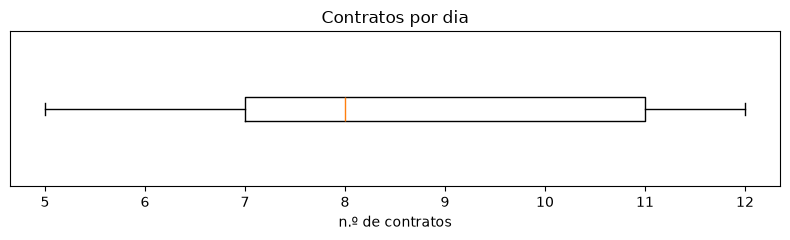

4.5 Sk1 = 0.71  Sk2 = 0.85  Bowley = 0.50 → assimétrica positiva (enviesada à direita)
    P10 = 5  P90 = 12  K = 0.286 → platicúrtica


In [ ]:
# Executar esta célula

"""Exercício 4 – Contratos por dia (dados não agrupados, sequência completa)."""
contratos = [12, 10, 12, 11, 11, 5, 7, 7, 10, 10, 8, 8, 7, 7, 5]
n = len(contratos)

print("4.1 Variável: n.º de contratos por dia — quantitativa discreta")
print("4.2 Tabela de frequências")
imprimir_tabela(tabela_frequencias(contratos), "contratos")

m, me, mo = media(contratos), mediana(contratos), moda(contratos)
s = desvio_padrao(contratos)
cv = coef_variacao(s, m)
print(f"4.3 média = {m:.4f}  mediana = {me}  moda = {mo}  s = {s:.4f}  "
      f"CV = {cv:.2f} % → {interpretar_cv(cv)}")

q1, _, q3 = quartis(contratos)
lim_m, lim_s, moderados, severos = outliers(contratos, q1, q3)
print(f"4.4 mín = {min(contratos)}  Q1 = {q1:g}  Me = {me}  Q3 = {q3:g}  "
      f"máx = {max(contratos)}  AIQ = {q3 - q1:g}")
print(f"    limites moderados {lim_m} → outliers: {moderados or 'nenhum'}")
diagrama_extremos_quartis(contratos, "Contratos por dia", "n.º de contratos")

p10, p90 = quantil(contratos, 0.10), quantil(contratos, 0.90)
sk1, sk2 = assimetria_pearson(m, me, s, mo[0])
bw = assimetria_bowley(q1, me, q3)
k = curtose_percentilica(q1, q3, p10, p90)
print(f"4.5 Sk1 = {sk1:.2f}  Sk2 = {sk2:.2f}  Bowley = {bw:.2f} → {classificar_assimetria(sk2)}")
print(f"    P10 = {p10:g}  P90 = {p90:g}  K = {k:.3f} → {classificar_curtose(k)}")

## Exercício 5 – Alturas dos alunos

**Dados:** 28 alturas, em cm.

**Leitura:** dados contínuos → Sturges (5 classes de 5 cm). As medidas de 5.5 calculam-se na tabela de classes (interpolação), como na solução oficial, e confirmam-se com os dados originais.


5.1 Sturges: k = 1 + 3,3·log10(28) ≈ 5.78 → 5 classes de 5 cm
            classe        c     n     N        f        F
       [150 ; 155[    152.5     3     3   0.1071   0.1071
       [155 ; 160[    157.5     5     8   0.1786   0.2857
       [160 ; 165[    162.5     7    15   0.2500   0.5357
       [165 ; 170[    167.5     7    22   0.2500   0.7857
       [170 ; 175]    172.5     6    28   0.2143   1.0000


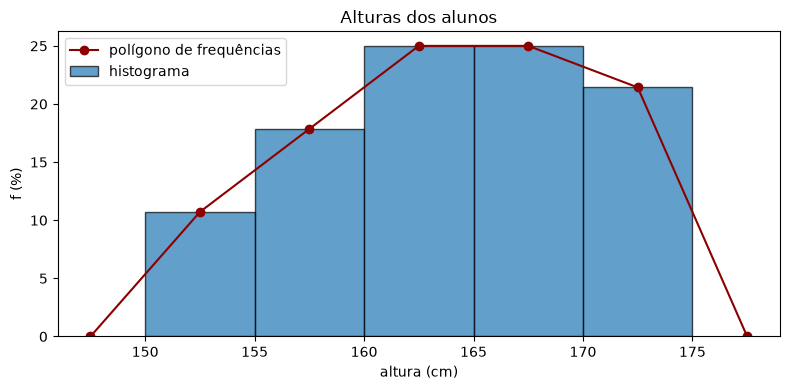

5.3 Classe(s) de maior efetivo: ['[160;165[', '[165;170[']
5.4 Pelo menos 1,65 m: 13/28 = 46.43 %
5.5 Com a tabela de classes (solução oficial):
    média = 163.93  mediana = 164.29  modas = [162.92, 167.31]
    Q1 = 159.00  Q3 = 169.29
    Dados originais: média = 163.32  Me = 164.0  modas = [158, 166]  s² = 40.89  s = 6.39  CV = 3.92 % → dispersão baixa
    amplitude total = 24 cm


In [ ]:
# Executar esta célula

"""Exercício 5 – Alturas (dados contínuos → classes pela regra de Sturges)."""
alturas = [150, 169, 174, 155, 165, 170, 172, 152, 158, 163, 158, 166, 158, 166,
           170, 171, 162, 171, 161, 154, 168, 161, 164, 166, 164, 162, 156, 167]
n = len(alturas)

k = sturges(n)
tab = classes_sturges(alturas, k=k, amplitude=5, inicio=150)   # 5 classes de 5 cm: 150 a 175
print(f"5.1 Sturges: k = 1 + 3,3·log10({n}) ≈ {1 + 3.3 * math.log10(n):.2f} → {k} classes de 5 cm")
imprimir_classes(tab, casas=0)
histograma(tab, "Alturas dos alunos", "altura (cm)")   # 5.2

modais = classe_modal(tab)
print("5.3 Classe(s) de maior efetivo:", [f"[{c['li']:.0f};{c['ls']:.0f}[" for c in modais])

pelo_menos_165 = sum(linha["n"] for linha in tab if linha["li"] >= 165)
print(f"5.4 Pelo menos 1,65 m: {pelo_menos_165}/{n} = {100 * pelo_menos_165 / n:.2f} %")

print("5.5 Com a tabela de classes (solução oficial):")
print(f"    média = {media_classes(tab):.2f}  mediana = {quantil_classes(tab, .5):.2f}  "
      f"modas = {[round(x, 2) for x in moda_classes(tab)]}")
print(f"    Q1 = {quantil_classes(tab, .25):.2f}  Q3 = {quantil_classes(tab, .75):.2f}")
m, s = media(alturas), desvio_padrao(alturas)
cv = coef_variacao(s, m)
print(f"    Dados originais: média = {m:.2f}  Me = {mediana(alturas)}  modas = {moda(alturas)}  "
      f"s² = {variancia(alturas):.2f}  s = {s:.2f}  CV = {cv:.2f} % → {interpretar_cv(cv)}")
print(f"    amplitude total = {max(alturas) - min(alturas)} cm")

## Exercício 6 – Satisfação dos alunos

**Dados:** notas médias de satisfação (1 a 5) de 35 alunos.

**Leitura:** Sturges → 6 classes de 0,6; classe modal e classe mediana; média e s com dados agrupados e não agrupados; quartis e diagrama com os dados originais.


6.1 Sturges → 6 classes de amplitude 0,6 a partir de 1,2
            classe        c     n     N        f        F
       [1.2 ; 1.8[     1.50     1     1   0.0286   0.0286
       [1.8 ; 2.4[     2.10     9    10   0.2571   0.2857
       [2.4 ; 3.0[     2.70     5    15   0.1429   0.4286
       [3.0 ; 3.6[     3.30     8    23   0.2286   0.6571
       [3.6 ; 4.2[     3.90    10    33   0.2857   0.9429
       [4.2 ; 4.8]     4.50     2    35   0.0571   1.0000


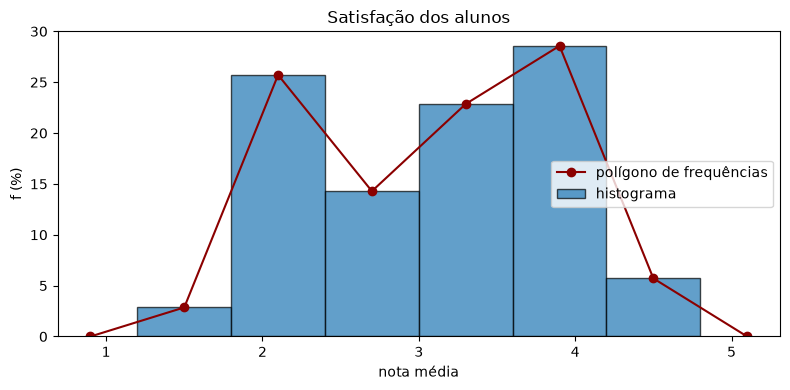

6.3 Classe modal: ['[3.6;4.2['] | classe mediana: [3.0;3.6[
6.4 não agrupados: média = 3.057  s = 0.857 | agrupados: média = 3.094  s = 0.822
    Agrupar substitui cada valor pelo ponto médio da classe: perde-se precisão, por isso os dados originais prevalecem.
6.5 mediana = 3.1  moda = [2.2]  Q1 = 2.3  Q3 = 3.8
6.6 mín = 1.2  Q1 = 2.3  Me = 3.1  Q3 = 3.8  máx = 4.5  outliers: nenhum


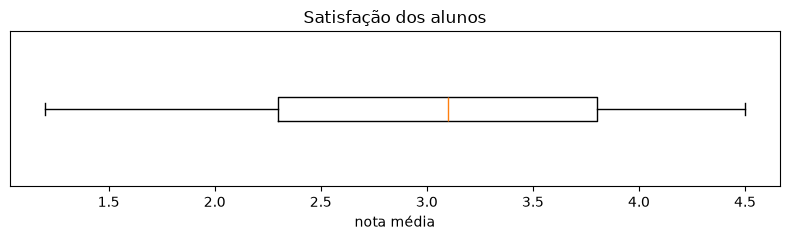

In [ ]:
# Executar esta célula

"""Exercício 6 – Satisfação dos alunos (classes pela regra de Sturges e dados originais)."""
notas = [2.4, 3.1, 4.5, 4.4, 3.9, 3.5, 3.4, 3.9, 2.4, 2.7, 2.8, 2.3, 4.1, 3.2,
         1.2, 3.8, 2.2, 2.3, 3.4, 2.2, 2.2, 4.1, 3.8, 3.7, 1.9, 3.3, 3.0, 3.0,
         4.0, 1.8, 2.2, 3.6, 1.8, 4.1, 2.8]
n = len(notas)
assert n == 35, "o enunciado tem 35 alunos"

k = sturges(n)                                   # 6
tab = classes_sturges(notas, k=k, amplitude=0.6, inicio=1.2)
print(f"6.1 Sturges → {k} classes de amplitude 0,6 a partir de 1,2")
imprimir_classes(tab)
histograma(tab, "Satisfação dos alunos", "nota média")   # 6.2

cm = classe_mediana(tab)
print("6.3 Classe modal:", [f"[{c['li']:.1f};{c['ls']:.1f}[" for c in classe_modal(tab)],
      f"| classe mediana: [{cm['li']:.1f};{cm['ls']:.1f}[")

m, s = media(notas), desvio_padrao(notas)
mg = media_classes(tab)
sg = desvio_padrao_ponderado([linha["c"] for linha in tab], [linha["n"] for linha in tab])
print(f"6.4 não agrupados: média = {m:.3f}  s = {s:.3f} | agrupados: média = {mg:.3f}  s = {sg:.3f}")
print("    Agrupar substitui cada valor pelo ponto médio da classe: perde-se precisão,"
      " por isso os dados originais prevalecem.")

q1, me, q3 = quartis(notas)
print(f"6.5 mediana = {me}  moda = {moda(notas)}  Q1 = {q1:g}  Q3 = {q3:g}")
lim_m, lim_s, moderados, severos = outliers(notas, q1, q3)
print(f"6.6 mín = {min(notas)}  Q1 = {q1:g}  Me = {me}  Q3 = {q3:g}  máx = {max(notas)}  "
      f"outliers: {moderados or 'nenhum'}")
diagrama_extremos_quartis(notas, "Satisfação dos alunos", "nota média")

## Exercício 7 – Q.I. de 80 crianças

**Dados:** 80 coeficientes de inteligência.

**Leitura:** Sturges → 7 classes de amplitude 11; a média pedida é a dos dados originais, porque estão disponíveis.


In [ ]:
# Executar esta célula

"""Exercício 7 – Q.I. de 80 crianças (Sturges com 7 classes)."""
qi = [111, 85, 82, 108, 85, 75, 112, 100, 133, 98, 106, 92, 102, 94, 91, 118,
      77, 94, 121, 100, 107, 115, 109, 100, 97, 102, 98, 101, 88, 104, 67, 111,
      106, 120, 91, 101, 103, 90, 93, 85, 98, 83, 98, 89, 106, 109, 100, 127,
      93, 100, 90, 102, 87, 79, 117, 85, 72, 98, 105, 122, 104, 95, 109, 133,
      116, 103, 56, 88, 107, 107, 94, 94, 99, 102, 108, 87, 80, 80, 119, 93]
n = len(qi)
assert n == 80

k = sturges(n)                                            # 7
h = (max(qi) - min(qi)) / k                               # 11
tab = classes_sturges(qi, k=k, amplitude=h, inicio=min(qi))
print(f"7.1 Sturges → {k} classes de amplitude {h:.0f} a partir de {min(qi)}")
imprimir_classes(tab, casas=0)
print(f"7.2 Q.I. médio (dados originais) = {media(qi):.3f} | "
      f"estimativa pelos pontos médios = {media_classes(tab):.2f}")

7.1 Sturges → 7 classes de amplitude 11 a partir de 56
            classe        c     n     N        f        F
         [56 ; 67[     61.5     1     1   0.0125   0.0125
         [67 ; 78[     72.5     4     5   0.0500   0.0625
         [78 ; 89[     83.5    13    18   0.1625   0.2250
        [89 ; 100[     94.5    21    39   0.2625   0.4875
       [100 ; 111[    105.5    27    66   0.3375   0.8250
       [111 ; 122[    116.5    10    76   0.1250   0.9500
       [122 ; 133]    127.5     4    80   0.0500   1.0000
7.2 Q.I. médio (dados originais) = 98.825 | estimativa pelos pontos médios = 99.31


## Exercício 8 – Prova de tiro

**Dados:** tiros certos (em 10) de 13 concorrentes.

**Leitura:** quantis pela posição (n + 1)/4; mostrar as posições ajuda a justificar. Um «bom atirador» está acima da mediana e perto de Q₃.


In [ ]:
# Executar esta célula

"""Exercício 8 – Prova de tiro (quantis de dados individuais)."""
tiros = [5, 6, 8, 5, 10, 7, 8, 5, 8, 7, 2, 9, 10]
q1, me, q3 = quartis(tiros)
n = len(tiros)
print(f"8.1 ordenados: {sorted(tiros)}")
print(f"    posições: Me = {(n + 1) / 2}  Q1 = {(n + 1) / 4}  Q3 = {3 * (n + 1) / 4}")
print(f"    mediana = {me}  Q1 = {q1:g}  Q3 = {q3:g}")
superados = sum(1 for x in tiros if x < 8)
melhores = sum(1 for x in tiros if x > 8)
print(f"8.2 Com 8 tiros: acima da mediana ({me}) e perto de Q3 ({q3:g}); "
      f"supera {superados} dos {n} concorrentes e só {melhores} fizeram melhor → bom atirador")

8.1 ordenados: [2, 5, 5, 5, 6, 7, 7, 8, 8, 8, 9, 10, 10]
    posições: Me = 7.0  Q1 = 3.5  Q3 = 10.5
    mediana = 7  Q1 = 5  Q3 = 8.5
8.2 Com 8 tiros: acima da mediana (7) e perto de Q3 (8.5); supera 7 dos 13 concorrentes e só 3 fizeram melhor → bom atirador


## Exercício 9 – Horas de instrução

**Dados:** tabela horas / n.º de alunos (n = 50).

**Leitura:** tabela valor/n.º → média ponderada; as posições dos quantis leem-se na coluna N; a moda é o valor com maior n.


In [ ]:
# Executar esta célula

"""Exercício 9 – Horas de instrução (tabela valor / n.º de alunos)."""
horas = [12, 13, 14, 15, 16, 17, 18, 19, 20]
alunos = [3, 6, 8, 10, 7, 6, 5, 3, 2]
tab = tabela_agrupada(horas, alunos)
n = sum(alunos)
imprimir_tabela(tab, "horas")

m = media_ponderada(horas, alunos)
soma = sum(h * a for h, a in zip(horas, alunos))
print(f"9.1 média = {soma}/{n} = {m:.2f} → cerca de 15 a 16 horas")
print(f"9.2 posições: Me {(n + 1) / 2}  Q1 {(n + 1) / 4}  Q3 {3 * (n + 1) / 4}, lidas na coluna N")
print(f"    mediana = {mediana_tabela(tab):g}  Q1 = {quantil_tabela(tab, .25):g}  "
      f"Q3 = {quantil_tabela(tab, .75):g}")
print(f"9.3 moda = {moda_tabela(tab)} horas (maior n = {max(alunos)})")

       horas      n      N        f        F
          12      3      3   0.0600   0.0600
          13      6      9   0.1200   0.1800
          14      8     17   0.1600   0.3400
          15     10     27   0.2000   0.5400
          16      7     34   0.1400   0.6800
          17      6     40   0.1200   0.8000
          18      5     45   0.1000   0.9000
          19      3     48   0.0600   0.9600
          20      2     50   0.0400   1.0000
9.1 média = 777/50 = 15.54 → cerca de 15 a 16 horas
9.2 posições: Me 25.5  Q1 12.75  Q3 38.25, lidas na coluna N
    mediana = 15  Q1 = 14  Q3 = 17
9.3 moda = [15] horas (maior n = 10)


## Exercício 10 – Ocupantes por veículo

**Dados:** tabela de 1 a 4 ocupantes / n.º de veículos (n = 1000).

**Leitura:** sequência completa numa tabela valor/n.º; quantis lidos na coluna N; Pearson negativo, K > 0,263 e sem outliers.


In [ ]:
# Executar esta célula

"""Exercício 10 – Ocupantes por veículo (tabela valor / n.º, sequência completa)."""
ocupantes = [1, 2, 3, 4]
veiculos = [150, 275, 320, 255]
tab = tabela_agrupada(ocupantes, veiculos)
n = sum(veiculos)
dados = [x for x, ni in zip(ocupantes, veiculos) for _ in range(ni)]   # lista expandida (1000 valores)

print("10.1 Variável: n.º de ocupantes por veículo — quantitativa discreta; unidade: veículo")
imprimir_tabela(tab, "ocupantes")
print("10.2 2 ou menos:", next(linha["N"] for linha in tab if linha["x"] == 2), "veículos")
entre = sum(ni for x, ni in zip(ocupantes, veiculos) if 3 <= x <= 4)
print(f"10.3 entre 3 e 4 inclusive: {100 * entre / n:.1f} %")
mo, me, m = moda_tabela(tab), mediana_tabela(tab), media_ponderada(ocupantes, veiculos)
print(f"10.4 moda = {mo}   10.5 mediana = {me:g}   10.6 média = {m}")
q1, q3 = quantil_tabela(tab, .25), quantil_tabela(tab, .75)
print(f"10.7 Q1 = {q1:g}  Q3 = {q3:g}   "
      f"10.8 D2 = {quantil_tabela(tab, .2):g}  D7 = {quantil_tabela(tab, .7):g}")
print(f"10.9 P35 = {quantil_tabela(tab, .35):g}  P60 = {quantil_tabela(tab, .6):g}  "
      f"P85 = {quantil_tabela(tab, .85):g}")

s = desvio_padrao_ponderado(ocupantes, veiculos)
p10, p90 = quantil_tabela(tab, .1), quantil_tabela(tab, .9)
sk1, sk2 = assimetria_pearson(m, me, s, mo[0])
k = curtose_percentilica(q1, q3, p10, p90)
print(f"10.10 s = {s:.4f}  Sk1 = {sk1:.2f}  Sk2 = {sk2:.2f}  "
      f"Bowley = {assimetria_bowley(q1, me, q3):.2f} → {classificar_assimetria(sk2)}")
print(f"      K = {k:.3f} → {classificar_curtose(k)}")
lim_m, lim_s, moderados, severos = outliers(dados, q1, q3)
print(f"10.11 limites moderados {lim_m}, severos {lim_s} → outliers: "
      f"{'nenhum' if not moderados and not severos else (moderados, severos)}")

10.1 Variável: n.º de ocupantes por veículo — quantitativa discreta; unidade: veículo
   ocupantes      n      N        f        F
           1    150    150   0.1500   0.1500
           2    275    425   0.2750   0.4250
           3    320    745   0.3200   0.7450
           4    255   1000   0.2550   1.0000
10.2 2 ou menos: 425 veículos
10.3 entre 3 e 4 inclusive: 57.5 %
10.4 moda = [3]   10.5 mediana = 3   10.6 média = 2.68
10.7 Q1 = 2  Q3 = 4   10.8 D2 = 2  D7 = 3
10.9 P35 = 2  P60 = 3  P85 = 4
10.10 s = 1.0142  Sk1 = -0.32  Sk2 = -0.95  Bowley = 0.00 → assimétrica negativa (enviesada à esquerda)
      K = 0.333 → platicúrtica
10.11 limites moderados (-1.0, 7.0), severos (-4.0, 10.0) → outliers: nenhum


## Exercício 11 – Composição de iogurtes

**Dados:** 7 iogurtes naturais e 13 normais e de frutas; proteínas, lípidos e hidratos de carbono (g).

**Leitura:** dois grupos × três variáveis, guardados em dicionários; compara médias e s. Para «maior dispersão», apresenta s e CV e diz qual critério usaste.


In [ ]:
# Executar esta célula

"""Exercício 11 – Composição de iogurtes (dois grupos, três variáveis)."""
naturais = {                      # 7 embalagens
    "proteinas": [6.6, 5.4, 5.4, 6.2, 5.0, 5.6, 5.8],
    "lipidos":   [0.5, 0.5, 3.7, 1.5, 2.3, 0.2, 0.3],
    "hidratos":  [8.4, 5.9, 15.6, 10.4, 6.5, 5.1, 6.2]}
normais = {                       # 13 embalagens
    "proteinas": [5.3, 4.8, 4.7, 5.4, 4.0, 2.8, 3.7, 3.9, 4.5, 3.2, 4.1, 3.7, 5.3],
    "lipidos":   [2.5, 1.4, 2.1, 4.1, 3.0, 0.5, 1.4, 11.5, 2.4, 3.5, 2.8, 3.0, 3.8],
    "hidratos":  [16.9, 22.0, 16.0, 12.0, 20.2, 11.0, 4.4, 12.0, 12.0, 15.0, 10.7, 14.0, 18.0]}

prot = naturais["proteinas"] + normais["proteinas"]
print(f"11.1 proteínas (n = {len(prot)}): média = {media(prot):.2f} g  s = {desvio_padrao(prot):.3f} g")

print("11.2 comparação por grupo (média, s, CV)")
for var in ("hidratos", "lipidos"):
    for nome, grupo in (("naturais", naturais), ("normais e frutas", normais)):
        d = grupo[var]
        m, s = media(d), desvio_padrao(d)
        print(f"     {var:9} {nome:17} n={len(d):2}  média={m:6.2f}  s={s:5.2f}  "
              f"CV={coef_variacao(s, m):6.1f} %")

ln, lf = naturais["lipidos"], normais["lipidos"]
print(f"11.3 lípidos: s naturais = {desvio_padrao(ln):.2f} | s normais = {desvio_padrao(lf):.2f}"
      " → maior dispersão absoluta: normais e frutas (solução oficial)")
print(f"     CV naturais = {coef_variacao(desvio_padrao(ln), media(ln)):.1f} % | "
      f"CV normais = {coef_variacao(desvio_padrao(lf), media(lf)):.1f} % → em termos relativos, naturais")
q1, _, q3 = quartis(lf)
_, _, moderados, severos = outliers(lf, q1, q3)
print(f"     outliers nos lípidos (normais): moderados {moderados or 'nenhum'}, severos {severos or 'nenhum'}")

11.1 proteínas (n = 20): média = 4.77 g  s = 1.012 g
11.2 comparação por grupo (média, s, CV)
     hidratos  naturais          n= 7  média=  8.30  s= 3.68  CV=  44.4 %
     hidratos  normais e frutas  n=13  média= 14.17  s= 4.61  CV=  32.6 %
     lipidos   naturais          n= 7  média=  1.29  s= 1.31  CV= 101.8 %
     lipidos   normais e frutas  n=13  média=  3.23  s= 2.68  CV=  83.1 %
11.3 lípidos: s naturais = 1.31 | s normais = 2.68 → maior dispersão absoluta: normais e frutas (solução oficial)
     CV naturais = 101.8 % | CV normais = 83.1 % → em termos relativos, naturais
     outliers nos lípidos (normais): moderados nenhum, severos [11.5]


## Exercício 12 – Salários

**Dados:** 600 colaboradores em 7 classes de 250 €.

**Leitura:** as classes vêm dadas → tudo por interpolação; os quantificadores leem-se nos limites das classes; Pearson positivo, K < 0,263; outliers acima do limite superior.

**Atenção a 12.6 e 12.7:** com classes [a ; b[, «até 1000 €» e «no máximo 750 €» incluem o próprio limite, mas a tabela não diz quantos salários são exatamente iguais a 1000 € ou a 750 €. A resposta usual (35 % e 440) é uma aproximação que trata o limite como se pertencesse à classe anterior.


12.1 Tabela completa
            classe        c     n     N        f        F
       [250 ; 500[    375.0    60    60   0.1000   0.1000
       [500 ; 750[    625.0   150   210   0.2500   0.3500
      [750 ; 1000[    875.0   230   440   0.3833   0.7333
     [1000 ; 1250[   1125.0    70   510   0.1167   0.8500
     [1250 ; 1500[   1375.0    43   553   0.0717   0.9217
     [1500 ; 1750[   1625.0    32   585   0.0533   0.9750
     [1750 ; 2000]   1875.0    15   600   0.0250   1.0000


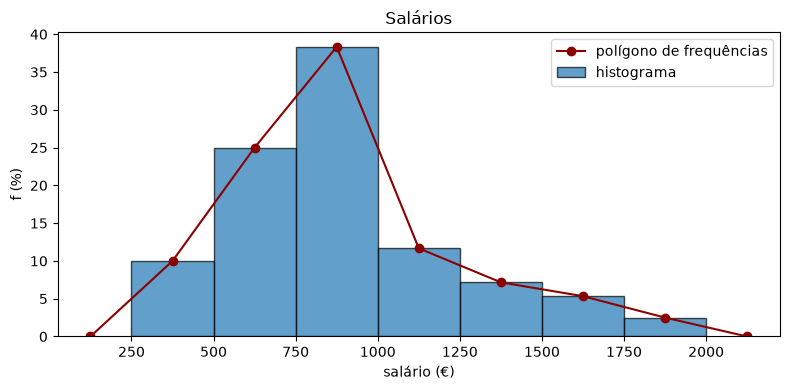

12.3 no mínimo 1000 €: 26.7 %
12.4 pelo menos 750 €: 65.0 %
12.5 entre 1250 e 1750 €: 12.5 %
12.6 no máximo 750 €: 35.0 % (aproximação: ver nota acima)
12.7 até 1000 €: 440 colaboradores (idem)
12.8 média = 892.50  mediana = 847.83  moda = 829.55  classe modal = [750;1000[
12.9 s² = 120728.30  s = 347.46  CV = 38.93 % → dispersão elevada
12.10 Q1=650.00 Q3=1035.71 D2=600.00 D4=782.61 P10=500.00 P90=1424.42
12.11 Sk1 = 0.18  Sk2 = 0.39  Bowley = -0.03 → assimétrica positiva (enviesada à direita); K = 0.209 → leptocúrtica
12.12 AIQ = 385.71; moderados fora de [71.43; 1614.29]; severos fora de [-507.14; 2192.86]
      → pelo menos 15 outliers moderados superiores ([1750;2000])
        a classe [1500;1750[ atravessa o limite: alguns dos seus 32 salários podem ser outliers, mas a tabela não diz quantos
      inferiores: nenhum; severos: nenhum


In [ ]:
# Executar esta célula

"""Exercício 12 – Salários (classes dadas no enunciado, sequência completa)."""
limites = [250, 500, 750, 1000, 1250, 1500, 1750, 2000]
freqs = [60, 150, 230, 70, 43, 32, 15]
tab = classes_dadas(limites, freqs)
n = sum(freqs)

print("12.1 Tabela completa")
imprimir_classes(tab, casas=0)
histograma(tab, "Salários", "salário (€)")   # 12.2


def F_ate(limite):
    """Frequência relativa acumulada das classes que terminam até `limite`."""
    return sum(linha["f"] for linha in tab if linha["ls"] <= limite)


print(f"12.3 no mínimo 1000 €: {100 * (1 - F_ate(1000)):.1f} %")
print(f"12.4 pelo menos 750 €: {100 * (1 - F_ate(750)):.1f} %")
print(f"12.5 entre 1250 e 1750 €: {100 * (F_ate(1750) - F_ate(1250)):.1f} %")
print(f"12.6 no máximo 750 €: {100 * F_ate(750):.1f} % (aproximação: ver nota acima)")
print(f"12.7 até 1000 €: {sum(linha['n'] for linha in tab if linha['ls'] <= 1000)} colaboradores (idem)")

m, me, mo = media_classes(tab), quantil_classes(tab, .5), moda_classes(tab)[0]
cmod = classe_modal(tab)[0]
print(f"12.8 média = {m:.2f}  mediana = {me:.2f}  moda = {mo:.2f}  "
      f"classe modal = [{cmod['li']};{cmod['ls']}[")
s2 = variancia_ponderada([linha["c"] for linha in tab], freqs)
s = math.sqrt(s2)
cv = coef_variacao(s, m)
print(f"12.9 s² = {s2:.2f}  s = {s:.2f}  CV = {cv:.2f} % → {interpretar_cv(cv)}")

q = {p: quantil_classes(tab, p) for p in (.25, .75, .2, .4, .1, .9)}
print(f"12.10 Q1={q[.25]:.2f} Q3={q[.75]:.2f} D2={q[.2]:.2f} D4={q[.4]:.2f} "
      f"P10={q[.1]:.2f} P90={q[.9]:.2f}")
sk1, sk2 = assimetria_pearson(m, me, s, mo)
k = curtose_percentilica(q[.25], q[.75], q[.1], q[.9])
print(f"12.11 Sk1 = {sk1:.2f}  Sk2 = {sk2:.2f}  Bowley = {assimetria_bowley(q[.25], me, q[.75]):.2f}"
      f" → {classificar_assimetria(sk2)}; K = {k:.3f} → {classificar_curtose(k)}")

aiq = q[.75] - q[.25]
lim_inf, lim_sup = q[.25] - 1.5 * aiq, q[.75] + 1.5 * aiq
sev_inf, sev_sup = q[.25] - 3 * aiq, q[.75] + 3 * aiq
print(f"12.12 AIQ = {aiq:.2f}; moderados fora de [{lim_inf:.2f}; {lim_sup:.2f}]; "
      f"severos fora de [{sev_inf:.2f}; {sev_sup:.2f}]")
acima = [linha for linha in tab if linha["li"] >= lim_sup]            # classes inteiras acima do limite
cruzam = [linha for linha in tab if linha["li"] < lim_sup < linha["ls"]]
certos = sum(linha["n"] for linha in acima)
nomes = ", ".join(f"[{c['li']};{c['ls']}]" for c in acima)
print(f"      → pelo menos {certos} outliers moderados superiores ({nomes})")
for c in cruzam:
    print(f"        a classe [{c['li']};{c['ls']}[ atravessa o limite: alguns dos seus {c['n']} "
          "salários podem ser outliers, mas a tabela não diz quantos")
ha_inferiores = tab[0]["li"] < lim_inf
ha_severos = tab[-1]["ls"] > sev_sup or tab[0]["li"] < sev_inf
print(f"      inferiores: {'possíveis' if ha_inferiores else 'nenhum'}; "
      f"severos: {'possíveis' if ha_severos else 'nenhum'}")

## Verificação automática contra as soluções oficiais

À mão, comparavas o teu resultado com a solução. 
Em programação, essa comparação também se escreve em código: a função `confere` compara cada valor calculado com o valor oficial, arredondado às mesmas casas decimais, e assinala as diferenças. 
Este é o princípio dos **testes automáticos**: se mais tarde alterares uma função da biblioteca, basta voltar a executar esta célula para saber se continua tudo certo.

A célula recalcula os valores a partir dos dados de cada exercício, por isso executa primeiro os exercícios 4 a 12.


In [ ]:
# Executar esta célula

import statistics

falhas = []


def confere(descricao, obtido, oficial, casas=2):
    certo = round(obtido, casas) == round(oficial, casas)
    if not certo:
        falhas.append(descricao)
    print(f"{'✓' if certo else '✗'} {descricao:<36} obtido {obtido:.{casas}f} | oficial {oficial:.{casas}f}")


t5 = classes_sturges(alturas, k=5, amplitude=5, inicio=150)
t6 = classes_sturges(notas, k=sturges(35), amplitude=0.6, inicio=1.2)
t9 = tabela_agrupada(horas, alunos)
t10 = tabela_agrupada(ocupantes, veiculos)
t12 = classes_dadas(limites, freqs)
m12 = media_classes(t12)
s12 = math.sqrt(variancia_ponderada([c["c"] for c in t12], freqs))

confere("4.3 CV dos contratos (%)", coef_variacao(desvio_padrao(contratos), media(contratos)), 27.12)
q1, _, q3 = quartis(contratos)
confere("4.5 K dos contratos", curtose_percentilica(q1, q3, quantil(contratos, .1), quantil(contratos, .9)), 0.286, 3)
confere("5.5 média (classes)", media_classes(t5), 163.93)
confere("5.5 mediana (classes)", quantil_classes(t5, .5), 164.29)
confere("5.5 1.ª moda (classes)", moda_classes(t5)[0], 162.92)
confere("5.5 2.ª moda (classes)", moda_classes(t5)[1], 167.31)
confere("5.5 Q1 (classes)", quantil_classes(t5, .25), 159.00)
confere("5.5 Q3 (classes)", quantil_classes(t5, .75), 169.29)
confere("5.5 s (dados originais)", desvio_padrao(alturas), 6.39)
confere("6   n.º de classes (Sturges)", sturges(len(notas)), 6, 0)
confere("6.4 média (agrupados)", media_classes(t6), 3.094, 3)
confere("7.2 Q.I. médio", media(qi), 98.825, 3)
confere("8.1 mediana", mediana(tiros), 7)
confere("8.1 Q1", quantil(tiros, .25), 5)
confere("8.1 Q3", quantil(tiros, .75), 8.5)
confere("9.1 média (horas)", media_ponderada(horas, alunos), 15.54)
confere("9.2 mediana (horas)", mediana_tabela(t9), 15)
confere("9.2 Q1 (horas)", quantil_tabela(t9, .25), 14)
confere("9.2 Q3 (horas)", quantil_tabela(t9, .75), 17)
confere("10.6 média (ocupantes)", media_ponderada(ocupantes, veiculos), 2.68)
confere("10.10 K (ocupantes)", curtose_percentilica(quantil_tabela(t10, .25), quantil_tabela(t10, .75),
                                                   quantil_tabela(t10, .1), quantil_tabela(t10, .9)), 0.333, 3)
confere("11.1 σ proteínas (divisor n)", statistics.pstdev(prot), 0.986, 3)
confere("11.2 média hidratos (naturais)", media(naturais["hidratos"]), 8.30)
confere("11.2 média hidratos (normais)", media(normais["hidratos"]), 14.17)
confere("11.2 média lípidos (naturais)", media(naturais["lipidos"]), 1.29)
confere("11.2 média lípidos (normais)", media(normais["lipidos"]), 3.23)
confere("12.8 média (salários)", m12, 892.50)
confere("12.8 mediana (salários)", quantil_classes(t12, .5), 847.83)
confere("12.8 moda (salários)", moda_classes(t12)[0], 829.55)
confere("12.9 s (salários)", s12, 347.46)
confere("12.9 CV (salários, %)", coef_variacao(s12, m12), 38.93)

print()
print("Tudo confere com as soluções oficiais." if not falhas else f"Diferenças: {falhas}")

✓ 4.3 CV dos contratos (%)             obtido 27.12 | oficial 27.12
✓ 4.5 K dos contratos                  obtido 0.286 | oficial 0.286
✓ 5.5 média (classes)                  obtido 163.93 | oficial 163.93
✓ 5.5 mediana (classes)                obtido 164.29 | oficial 164.29
✓ 5.5 1.ª moda (classes)               obtido 162.92 | oficial 162.92
✓ 5.5 2.ª moda (classes)               obtido 167.31 | oficial 167.31
✓ 5.5 Q1 (classes)                     obtido 159.00 | oficial 159.00
✓ 5.5 Q3 (classes)                     obtido 169.29 | oficial 169.29
✓ 5.5 s (dados originais)              obtido 6.39 | oficial 6.39
✓ 6   n.º de classes (Sturges)         obtido 6 | oficial 6
✓ 6.4 média (agrupados)                obtido 3.094 | oficial 3.094
✓ 7.2 Q.I. médio                       obtido 98.825 | oficial 98.825
✓ 8.1 mediana                          obtido 7.00 | oficial 7.00
✓ 8.1 Q1                               obtido 5.00 | oficial 5.00
✓ 8.1 Q3                               obtido 8.

**A única divergência conhecida é a de 11.1.** A solução oficial calcula o desvio-padrão das proteínas com divisor n (σ = 0,986), enquanto os slides usam n − 1 (s = 1,012). Por isso a verificação acima usa `statistics.pstdev` (divisor n) nessa linha. A célula seguinte mostra as duas versões lado a lado.


In [ ]:
# Executar esta célula

print(f"s (divisor n − 1, slides)        = {statistics.stdev(prot):.3f}")
print(f"σ (divisor n, solução oficial)   = {statistics.pstdev(prot):.3f}")

s (divisor n − 1, slides)        = 1.012
σ (divisor n, solução oficial)   = 0.986


## Experimenta

Altera os dados de um exercício e volta a executar a célula (e depois a verificação, para veres o que deixa de conferir):
- no ex. 4, troca um 12 por um 20: em 4.4 aparece um outlier e em 4.5 a assimetria aumenta;
- no ex. 12, muda a frequência da última classe de 15 para 60 e observa K, os limites de outliers e quantas classes os ultrapassam;
- no ex. 6, muda a amplitude das classes para 0,5 e compara a média agrupada com a dos dados originais.


### Exercício – Percentagem com uma condição

Nos exercícios 2, 5 e 10 contaste valores que cumprem uma condição («inferior a 222», «pelo menos 165», «entre 3 e 4»). Escreve uma função `percentagem(dados, condicao)` que recebe uma lista e uma função `condicao` e devolve a percentagem de valores que a cumprem. Usa-a com expressões lambda (capítulo 19) para refazer 2.5 e 5.4.


In [23]:
# Escreve aqui o teu código

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def percentagem(dados, condicao):
    return 100 * sum(1 for x in dados if condicao(x)) / len(dados)


print(f"2.5 {percentagem(bolsas, lambda x: x < 222):.0f} %")      # 84 %
print(f"5.4 {percentagem(alturas, lambda x: x >= 165):.2f} %")   # 46.43 %
```

</details>


## Verifica o que aprendeste

1. Porque é que a função `quantil` foi escrita à mão em vez de usar uma biblioteca?
2. No ex. 6, porque é que a média dos dados agrupados (3,094) é diferente da dos dados originais (3,057)? Qual deves preferir?
3. Que diferença faz usar o divisor n ou n − 1 na variância? Em que alínea isso muda o resultado oficial?
4. Porque é que `diagrama_extremos_quartis` usa `ax.bxp` e não `ax.boxplot`?
5. No ex. 12.12, porque não se pode dizer exatamente quantos salários são outliers?

<details>
<summary><b>Ver respostas</b></summary>

1. Para perceber o método e controlar a convenção. Há vários métodos de quantis: o `statistics.quantiles` usa por omissão o da disciplina (posição p·(n + 1)), mas o NumPy, o pandas e o matplotlib usam outro e dão valores diferentes. A função própria garante os valores das soluções oficiais para qualquer ordem p (no módulo seguinte vês como escolher o método no NumPy).
2. Ao agrupar, cada valor é substituído pelo ponto médio da sua classe, o que introduz um pequeno erro. Quando os dados originais estão disponíveis, preferem-se os resultados calculados com eles.
3. Com n − 1 obtém-se a variância amostral, um pouco maior, usada quando os dados são uma amostra; com n obtém-se a variância da população. A diferença nota-se mais com poucos dados: no ex. 11.1 dá 1,012 com n − 1 e 0,986 com n, que é o valor da solução oficial.
4. O `ax.boxplot` calcula os quartis com o método do NumPy (no ex. 4 daria Q₃ = 10,5). O `ax.bxp` só desenha os cinco números que lhe passamos, calculados com a convenção da disciplina (Q₃ = 11).
5. Com dados em classes não se conhecem os valores individuais. O limite superior (1614,29 €) cai dentro da classe [1500 ; 1750[, por isso só se sabe que os 15 salários da última classe são outliers e que alguns da penúltima podem sê-lo.

</details>


## Leitura recomendada

- Capítulos do curso usados aqui: 12 (Listas), 14 (Dicionários), 18 (Funções), 19 (Expressões lambda) e 24 (Visualização de dados).
- [Documentação do módulo `statistics`](https://docs.python.org/3/library/statistics.html) – média, mediana, moda, `stdev`/`pstdev` e `quantiles` na biblioteca padrão.
- [Documentação de `collections.Counter`](https://docs.python.org/3/library/collections.html#collections.Counter) – a base das tabelas de frequências.
- [Documentação de `Axes.bxp` no matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bxp.html) – desenhar diagramas de extremos e quartis a partir de valores já calculados.
- Hyndman, R. J. e Fan, Y. (1996). «Sample quantiles in statistical packages». *The American Statistician*, 50(4), 361–365 – o artigo de referência sobre os vários métodos de cálculo de quantis.
- Reis, E. (2009). *Estatística Descritiva* (7.ª ed.). Lisboa: Edições Sílabo.
- Curto, J. D. e Pinto, J. (2014). *Estatística para Economia e Gestão*. Lisboa: Edições Sílabo.
- **Módulo seguinte:** os mesmos exercícios com NumPy, Pandas e SciPy.
